# Monte Carlo Simulation to estimating area of a Lake

## The idea

We want the area of a lake with an irregular shape, for which there is no formula. But for any point on the map, we can easily tell whether it is **in the lake or not**.

The map is a square of $\text{size} \times \text{size}$ pixels. If we pick $n$ pixels uniformly at random and $M$ of them are in the lake, then the fraction of hits is close to the fraction of the map covered by the lake:

$$\frac{M}{n} \approx \frac{A}{\text{size}^2} \quad\Longrightarrow\quad A \approx \text{size}^2 \cdot \frac{M}{n}$$

This is exactly the same trick as for $\pi$: there the "lake" was a quarter disk.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

## Generating a random lake

To have something to measure, we build a random lake:

1. Start from one pixel near the centre of the map.
2. Repeatedly pick a random pixel on the border of the lake and add it to the lake. The lake grows like a stain of ink, with an irregular shape.
3. Fill the holes inside the lake and smooth its edges.

Step 3 adds a few pixels, so the final lake is slightly larger than the requested `area`.

In [2]:
def generate_lake(area, size, smooth=2, seed=None):
    from scipy import ndimage
    rng = np.random.default_rng(seed)
    lake = np.zeros((size, size), dtype=bool)
    frontier = []  # candidate pixels: outside the lake but touching it
    index = {}     # pixel -> position in frontier, for O(1) removal

    def add_pixel(x, y):
        lake[x, y] = True
        # Remove (x, y) from the frontier: swap with the last element, then pop
        i = index.pop((x, y), None)
        if i is not None:
            last = frontier.pop()
            if i < len(frontier):
                frontier[i] = last
                index[last] = i
        # Add its free neighbours (cross) to the frontier
        for nx, ny in ((x-1, y), (x+1, y), (x, y-1), (x, y+1)):
            if 0 <= nx < size and 0 <= ny < size and not lake[nx, ny] and (nx, ny) not in index:
                index[(nx, ny)] = len(frontier)
                frontier.append((nx, ny))

    x, y = rng.integers((size/2) - (size / 4), (size/2) + (size / 4), 2)
    add_pixel(int(x), int(y))
    for r in rng.random(area):  # random numbers drawn all at once
        if not frontier:        # grid is full
            break
        add_pixel(*frontier[int(r * len(frontier))])

    lake = ndimage.binary_fill_holes(lake)
    if smooth > 0:
        lake = ndimage.binary_closing(lake, structure=np.ones((3, 3)), iterations=smooth)
    return lake.astype(int)


In [3]:
def plot_lake(lake, title='Lake Representation'):
    colored_list = ['#78f249', '#8fced3']
    if(lake > 1).any():
        colored_list = ['#78f249', '#8fced3', '#000000']
    cmap = ListedColormap(colored_list)
    plt.imshow(lake, cmap=cmap, vmin=0, vmax=len(colored_list), interpolation='nearest')
    plt.title(title)
    plt.axis('off')
    plt.show()

(256, 256)


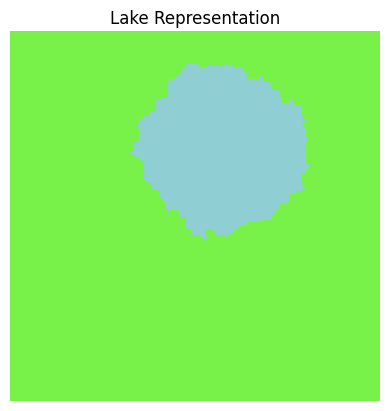

In [4]:
lake = generate_lake(area=10000, size=256)
print(lake.shape)
plot_lake(lake)

## The Monte Carlo estimate

We draw $n$ random pixels, count the $M$ that fall in the lake, and apply

$$\hat A = \text{size}^2 \cdot \frac{M}{n}$$

In the image below, the black dots are the random pixels we tested.

In [5]:
def monte_carlo(lake, num_samples=10000):
    size = lake.shape[0]
    samples = np.random.randint(0, size, (num_samples, 2))
    inside_count = sum(lake[x, y] for x, y in samples)
    area = (inside_count / num_samples) * (size * size)
    return samples, area

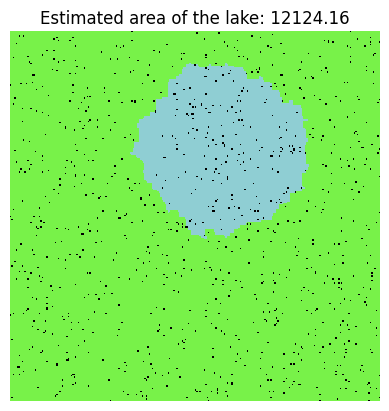

In [6]:
s, area = monte_carlo(lake, num_samples=1000)

new_lake = lake.copy()
new_lake[s[:, 0], s[:, 1]] = 2  # Mark the sampled points with a different value for visualization
plot_lake(new_lake, title=f'Estimated area of the lake: {area:.2f}')

# Benchmark Time

## How precise is the estimate?

As for $\pi$, each random pixel is a "yes / no" experiment: it falls in the lake with probability $p = A / \text{size}^2$ (here about $10\,000 / 256^2 \approx 0.16$). The **relative error** of the estimate is typically

$$\frac{|\hat A - A|}{A} \sim \sqrt{\frac{1-p}{p \, n}}$$

so it decreases like $1/\sqrt{n}$, as always with Monte Carlo. Note that a small lake (small $p$) needs more points for the same relative precision: most points are "wasted" on dry land.

To measure the error in practice, we repeat the experiment 10 000 times (with a new random lake each time) and look at the average error for each number of points $n$.

In [7]:
def step(area, size, samples, rng = None):
    lake = generate_lake(area, size)
    rng = np.random.default_rng(rng)

    n_max = samples.max()
    x = rng.integers(0, size, n_max)
    y = rng.integers(0, size, n_max)
    hits = np.cumsum(lake[x, y])

    estimated_area = size**2 * hits[samples - 1] / samples
    return np.abs(estimated_area - area) / area


In [8]:
AREA = 10000
SIZE = 256
ITERATIONS = 10000

from concurrent.futures import ProcessPoolExecutor, as_completed
from tqdm import tqdm


samples = np.arange(10, 10e3, 10, dtype=int)
#errors = np.array([step(AREA, SIZE, samples = samples) for _ in range(ITERATIONS)])
with ProcessPoolExecutor() as executor:
    futures = [executor.submit(step, AREA, SIZE, samples) for _ in range(ITERATIONS)]
    for _ in tqdm(as_completed(futures), total=ITERATIONS, desc="Processing"):
        pass
    errors = np.array([future.result() for future in futures])
print(errors.shape)

Processing: 100%|██████████| 10000/10000 [00:28<00:00, 346.41it/s]

(10000, 999)


In [9]:
import scipy
#mean_errors = scipy.signal.savgol_filter(errors.mean(axis=0), window_length=11, polyorder=2)
#std_errors  = scipy.signal.savgol_filter(errors.std(axis=0), window_length=11, polyorder=2) 
mean_errors = errors.mean(axis=0)
std_errors = errors.std(axis=0)

## Reading the plot

The blue curve is the average relative error as a function of the number of points $n$, and the shaded band shows how much it varies from one experiment to another. The error drops quickly at first, then more and more slowly: this is the $1/\sqrt{n}$ behaviour. Going from 1 000 to 10 000 points only divides the error by about $\sqrt{10} \approx 3$.

*Note:* the error is measured against the requested `AREA`, while the generated lake is a bit larger (holes filled, edges smoothed). This is why the curve levels off instead of going all the way down to 0.

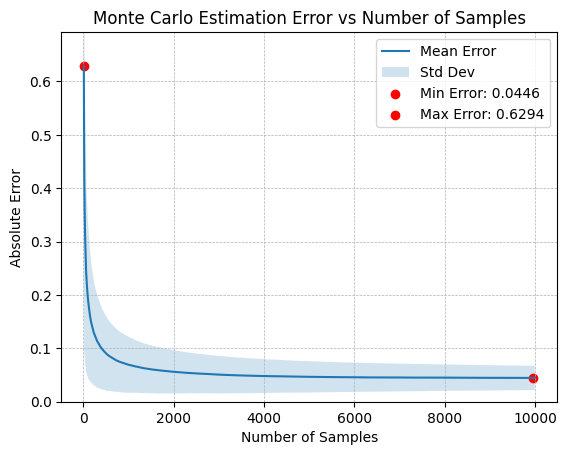

In [13]:
plt.plot(samples, mean_errors, label='Mean Error')
# Plot Theoretical error decay line (1/sqrt(n))
#plt.plot(samples, 1/np.sqrt(samples), label='Theoretical Decay (1/sqrt(n))', linestyle='--', color='orange')
plt.fill_between(samples, mean_errors - std_errors, mean_errors + std_errors, alpha=0.2, label='Std Dev')
plt.xlabel('Number of Samples')
plt.ylabel('Absolute Error')
plt.title('Monte Carlo Estimation Error vs Number of Samples')
# Plot point min and max of mean curves with values
plt.scatter(samples[np.argmin(mean_errors)], np.min(mean_errors), color='red', label=f'Min Error: {np.min(mean_errors):.4f}')
plt.scatter(samples[np.argmax(mean_errors)], np.max(mean_errors), color='red', label=f'Max Error: {np.max(mean_errors):.4f}')
plt.legend()
plt.ylim(0, np.max(mean_errors) * 1.1)
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.show()